# Проект: Влияние приложения для медитации на время засыпания

Тема «Постановка и проверка гипотез» \
уровень: начальный

---

## Сценарий

Компания разработала мобильное приложение с вечерними медитациями. Чтобы понять, помогает ли оно быстрее засыпать,
провели небольшое исследование. **Около 50 добровольцев** в течение одной недели фиксировали, сколько минут им требуется,
чтобы заснуть (среднее за неделю). Затем в течение 4 недель они пользовались приложением и ещё одну неделю
снова фиксировали время засыпания.

Данные получены **выгрузкой из системы сбора анкет**, поэтому, как и в реальной работе, они могут содержать ошибки.
Перед анализом их нужно проверить и очистить.

**Бизнес-вопрос:** *сокращает ли использование приложения время засыпания?*

Вы работаете аналитиком и должны ответить на него с помощью проверки статистических гипотез.

## Описание данных

| Столбец | Описание |
|---|---|
| `participant_id` | Идентификатор участника |
| `age` | Возраст участника (полных лет) |
| `before_min` | Среднее время засыпания (мин) за неделю **до** использования приложения |
| `after_min` | Среднее время засыпания (мин) за неделю **после** 4 недель использования |

Данные **парные**: каждая строка — один и тот же человек, измеренный дважды.
Возрастных групп в исходных данных **нет**: их нужно сформировать самостоятельно (задание 2).

## Допущения (упрощения для учебного проекта)

- Участники независимы друг от друга.
- Уровень значимости $\alpha = 0.05$ для всех проверок.
- Контрольной группы нет, поэтому причинно-следственные выводы ограничены (это нужно будет отметить в выводах).
- Допустимые значения (используются при очистке): время засыпания от **5 до 180 минут**, возраст от **18 до 80 лет**.

## Правила выполнения

1. Ячейку с генерацией данных **не изменяйте**. Также **нет необходимости изучать её код**: в реальной работе у вас нет кода, создавшего выгрузку, и проблемы в данных нужно находить анализом самой таблицы.
2. Каждый график должен иметь заголовок, подписи осей и (если нужно) легенду.
3. Решения о гипотезах, очистке данных и выбор тестов нужно **обосновывать словами**, а не только кодом.
4. Выводы формулируйте на языке бизнеса: без фраз вида «отвергаем H₀» в итоговом заключении.
5. Ноутбук должен выполняться целиком сверху вниз без ошибок (**Kernel → Restart & Run All**).

## Критерии оценки

| № | Задание | Баллы |
|---|---|:---:|
| 1 | Формулировка гипотез | 2 |
| 2 | Аудит и очистка данных, формирование возрастных групп | 4 |
| 3 | Разведочный анализ и графики | 2 |
| 4 | Проверка нормальности | 2 |
| 5 | Парный t-критерий и доверительный интервал | 2 |
| 6 | Критерий Уилкоксона | 1 |
| 7 | Сравнение с ошибочным непарным тестом | 2 |
| 8 | Размер эффекта | 1 |
| 9 | Гипотеза о доле улучшивших | 1 |
| 10 | Итоговые выводы | 1 |
| 11 | Оформление проекта (репозиторий, `requirements.txt`, воспроизводимость) | 2 |
| | **Итого** | **20** |
| ★ | Бонусное задание | +2 |

## Подготовка

Импортируйте нужные библиотеки в ячейке ниже (часть уже указана). При необходимости добавьте свои.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.options.display.float_format = "{:.6g}".format

ALPHA = 0.05
BLUE = "#3B6E8F"
ORANGE = "#BD792D"
GRAY = "#50565C"

### Данные

Выполните ячейку ниже. **Не изменяйте её и не изучайте её код** (см. правила выше): фиксированное зерно генератора (`seed`) гарантирует, что у всех получатся одинаковые данные.

In [2]:
rng = np.random.default_rng(150)
n = 50

age = rng.integers(18, 61, size=n).astype(float)
before = rng.normal(35, 10, n)
effect = np.where(age < 35, -4, -1)
after = before + rng.normal(effect, 4.5)

df = pd.DataFrame({
    "participant_id": range(1, n + 1),
    "age": age,
    "before_min": np.clip(before.round(), 5, None).astype(object),
    "after_min": np.clip(after.round(), 5, None).astype(object),
})

# --- Имитация реальной выгрузки: в ней бывают сбои и ошибки ввода ---
df.loc[[3, 17], "after_min"] = np.nan
df.loc[29, "before_min"] = np.nan
df.loc[8, "after_min"] = -20
df.loc[22, "before_min"] = 999
df.loc[41, "after_min"] = 400
df.loc[12, "before_min"] = f"{float(df.loc[12, 'before_min']):.1f}".replace(".", ",")
df.loc[36, "after_min"] = f"{float(df.loc[36, 'after_min']):.1f}".replace(".", ",")
df.loc[[5, 14], "age"] = np.nan
df.loc[19, "age"] = 0
df.loc[33, "age"] = 150
df = pd.concat([df, df.loc[[10, 25]]], ignore_index=True)
df = df.sample(frac=1, random_state=1).reset_index(drop=True)

df.head(10)

,participant_id,age,before_min,after_min
0,32,52,31,26
1,3,42,30,32
2,43,30,30,24
3,33,31,28,18
4,31,30,28,25
5,46,54,24,21
6,34,150,33,29
7,39,24,28,25
8,45,19,56,57
9,20,0,35,30


---
## Задание 1. Формулировка гипотез (2 балла)

**Что нужно сделать.** Запишите нулевую и альтернативную гипотезы для бизнес-вопроса
«сокращает ли приложение время засыпания?».

**Требования:**
- явно задайте разность $d_i$ (какой столбец из какого вычитается) и параметр $\mu_d$ (что он означает по-русски);
- запишите $H_0$ и $H_1$ формулами;
- обоснуйте выбор типа альтернативы (односторонняя или двусторонняя) в 1–2 предложениях;
- укажите правило принятия решения.

### Подсказки

- Данные парные, поэтому гипотезы формулируются **об одном параметре**: среднем значении разностей $\mu_d$, а не о двух средних.
- Определите разность как $d_i = \text{after}_i - \text{before}_i$. Подумайте, **какой знак** будет у $d_i$, если приложение помогает
  (время засыпания уменьшилось → разность положительная или отрицательная?). От этого зависит, в какую сторону направлена $H_1$.
- Направление альтернативы выбирается из логики задачи **до** просмотра результатов. Что именно хочет доказать компания?
- Для записи формул в Markdown используйте синтаксис `$\mu_d < 0$`.

### Ваш ответ

**Определение разности:** $d_i = \text{after\_min}_i - \text{before\_min}_i$.
Это изменение времени засыпания у одного участника в минутах.
Если человек стал засыпать быстрее, разность отрицательная.

**Параметр:** $\mu_d$ — среднее изменение времени засыпания в генеральной
совокупности, которую представляет выборка.

**H₀:** $\mu_d = 0$ — среднее время засыпания не изменилось.

**H₁:** $\mu_d < 0$ — среднее время засыпания сократилось.

**Обоснование типа альтернативы:** выбираем одностороннюю левостороннюю
альтернативу, поскольку вопрос исследования касается сокращения времени.
Направление выбираем по смыслу задачи до просмотра результатов тестов.

**Правило принятия решения:** при $p < 0.05$ отвергаем $H_0$ в пользу $H_1$.
При $p \geq 0.05$ оснований для этого недостаточно; отсутствие эффекта
при этом не считается доказанным.


---
## Задание 2. Аудит и очистка данных, формирование возрастных групп (4 балла)

**Что нужно сделать.** Исходная таблица `df` получена выгрузкой и **содержит проблемы с качеством данных**.
Вам нужно (1) найти их, (2) устранить по заданным правилам, (3) сформировать возрастные группы,
(4) зафиксировать, что и сколько было исправлено. Результат сохраните в новый датафрейм **`df_clean`**:
**все дальнейшие задания выполняются только на нём.** Исходный `df` не изменяйте (работайте с копией).

### 2.1. Аудит (поиск проблем)

Выведите и кратко прокомментируйте (по одному предложению на пункт):
- размер таблицы, типы столбцов, число непустых значений в каждом столбце;
- число пропусков по столбцам;
- число полных дубликатов строк и повторов `participant_id`;
- минимальные и максимальные значения числовых столбцов;
- столбцы, в которых тип данных **не соответствует ожидаемому** (какие значения этому мешают?).

Составьте **список обнаруженных проблем** (что именно не так и в каких столбцах).

### 2.2. Очистка по правилам

Применяйте правила **строго в указанном порядке**:

| № | Правило |
|---|---|
| 1 | **Типы.** Столбцы `before_min` и `after_min` привести к числовому типу. Значения, записанные текстом с десятичной запятой (например, `"31,0"`), преобразовать в числа. Значения, которые преобразовать невозможно, считать пропусками. |
| 2 | **Дубликаты.** Удалить полные дубликаты строк (оставить первое вхождение). |
| 3 | **Допустимые диапазоны.** Время засыпания допустимо в диапазоне **[5; 180]** минут, возраст допустим в диапазоне **[18; 80]** лет. Значения вне диапазона считать ошибками и заменить на пропуски. |
| 4 | **Неполные пары.** Удалить участников, у которых отсутствует **хотя бы одно** из двух значений времени (`before_min`, `after_min`). Участников с неизвестным возрастом **не удалять**: возраст нужен только для возрастных групп. |

### 2.3. Формирование возрастных групп

Создайте в `df_clean` столбец `age_group` по правилу:

| Условие | Значение `age_group` |
|---|---|
| `age` < 35 | `"до 35"` |
| `age` ≥ 35 | `"35 и старше"` |
| возраст неизвестен (пропуск) | пропуск (не заполнять средним и не относить ни к одной группе) |

### 2.4. Журнал очистки

Оформите **таблицей** (`pd.DataFrame`) журнал: для каждого шага — что сделано, сколько значений или строк затронуто, сколько строк осталось после шага.
Затем ответьте письменно (2–3 предложения): **почему** участников с пропусками во времени мы удаляем, а не заполняем средним значением?

**Контроль результата:** в `df_clean` должно остаться **44 строки**, а столбец `age_group` должен быть заполнен у **40** из них.
Если у вас получились другие числа, проверьте порядок применения правил.

### Подсказки

**Аудит.**
- `df.info()` показывает типы столбцов и число непустых значений: если столбец с числами имеет тип `object`, в нём есть текстовые значения.
- Пропуски: `df.isna().sum()`. Полные дубликаты: `df.duplicated().sum()`. Повторы только по идентификатору: `.duplicated()` у столбца `participant_id`.
- `df.describe()` по умолчанию описывает только числовые столбцы. Чтобы увидеть, какие именно значения в текстовом столбце «не числа», преобразуйте
  его функцией `pd.to_numeric(..., errors="coerce")`: всё, что не удалось преобразовать, станет `NaN`. Сравните с исходным столбцом и найдите значения,
  которые превратились в `NaN`, хотя раньше пропусками не были.
- Нереальные значения проще всего найти, отсортировав столбец (`sort_values`) и посмотрев на самые маленькие и самые большие значения,
  либо построив гистограмму или boxplot **после** преобразования типа.

**Очистка.**
- Работайте с копией: `df_clean = df.copy()`. Это защитит исходные данные и избавит от предупреждения `SettingWithCopyWarning`.
- Замена запятой на точку: у текстового столбца есть `.str.replace(",", ".")`. Но в столбце смешаны числа и строки, поэтому сначала приведите всё к строкам
  (`.astype(str)`), а затем преобразуйте в числа через `pd.to_numeric(..., errors="coerce")`. Пропуски при этом снова станут `NaN`.
- Дубликаты: `drop_duplicates()`.
- Замена значений вне диапазона на пропуски: можно через булеву маску и `.loc[маска, столбец] = np.nan`, либо через `Series.where(...)` / `Series.between(...)`.
  Не забудьте, что условие нужно составить для **обеих границ**.
- Удаление неполных пар: `dropna(subset=[...])`. Обратите внимание на параметр `subset`: без него будут удалены и строки с неизвестным возрастом.
- После очистки типы столбцов `before_min` и `after_min` должны быть числовыми (`float`). Проверьте через `df_clean.dtypes`.

**Возрастные группы.**
- Вариант 1: `pd.cut(df_clean["age"], bins=[...], labels=[...], right=False)`. Подумайте, как параметр `right` влияет на то, куда попадает возраст ровно 35.
- Вариант 2: `np.where(условие, значение_если_верно, значение_если_неверно)`. **Ловушка:** сравнение с `NaN` всегда ложно (`NaN < 35` это `False`),
  поэтому при простом `np.where(age < 35, "до 35", "35 и старше")` неизвестный возраст молча попадёт в группу «35 и старше». Предусмотрите отдельную обработку пропусков.
- Проверьте результат: `df_clean["age_group"].value_counts(dropna=False)` покажет и число пропусков.

**Журнал и обоснование.**
- Журнал удобно вести, запоминая `len(df_clean)` до и после каждого шага и добавляя строки в список словарей, из которого потом строится `pd.DataFrame`.
- Для обоснования подумайте: что произойдёт с парной разностью $d_i = \text{after}_i - \text{before}_i$, если подставить вместо пропущенного значения среднее по столбцу?
  Будет ли такая «разность» отражать реальное изменение у конкретного человека?

### Ваше решение

### 2.1. Аудит данных

In [3]:
print("Размер исходной таблицы:", df.shape)
df.info()

display(pd.DataFrame({
    "Тип": df.dtypes.astype(str),
    "Непустых": df.notna().sum(),
    "Пропусков": df.isna().sum(),
}))

print("Полных дубликатов:", df.duplicated().sum())
print("Повторов participant_id:", df["participant_id"].duplicated().sum())

audit_numbers = pd.DataFrame(index=df.index)
text_values = []

for column in ["age", "before_min", "after_min"]:
    values = df[column].astype(str).str.replace(",", ".", regex=False)
    audit_numbers[column] = pd.to_numeric(values, errors="coerce")

    text_mask = df[column].map(lambda value: isinstance(value, str))
    for index in df.index[text_mask]:
        text_values.append({
            "participant_id": df.loc[index, "participant_id"],
            "Столбец": column,
            "Текстовое значение": df.loc[index, column],
        })

print("Минимумы и максимумы до очистки:")
display(audit_numbers.agg(["min", "max"]).T)

print("Числа, записанные текстом:")
display(pd.DataFrame(text_values))

print("Значения вне допустимых диапазонов:")
for column, lower, upper in [
    ("before_min", 5, 180),
    ("after_min", 5, 180),
    ("age", 18, 80),
]:
    values = audit_numbers[column]
    invalid = values.notna() & ~values.between(lower, upper)
    print(column, ":", values[invalid].tolist())

Размер исходной таблицы: (52, 4)
<class 'pandas.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   participant_id  52 non-null     int64  
 1   age             50 non-null     float64
 2   before_min      51 non-null     object 
 3   after_min       50 non-null     object 
dtypes: float64(1), int64(1), object(2)
memory usage: 1.8+ KB


,Тип,Непустых,Пропусков
participant_id,int64,52,0
age,float64,50,2
before_min,object,51,1
after_min,object,50,2


Полных дубликатов: 2
Повторов participant_id: 2
Минимумы и максимумы до очистки:


,min,max
age,0,150
before_min,5,999
after_min,-20,400


Числа, записанные текстом:


,participant_id,Столбец,Текстовое значение
0,13,before_min,"37,0"
1,37,after_min,"18,0"


Значения вне допустимых диапазонов:
before_min : [999.0]
after_min : [400.0, -20.0]
age : [150.0, 0.0]


**Результаты аудита:**

1. В исходной таблице 52 строки и 4 столбца; столбцы времени имеют тип `object`, хотя ожидаются числа.
2. Пропуски по столбцам: `age` — 2, `before_min` — 1, `after_min` — 2; в `participant_id` пропусков нет.
3. Найдено 2 полных дубликата строки и 2 повтора идентификатора.
4. Время до использования лежит от 5 до 999 минут, после — от -20 до 400 минут; возраст — от 0 до 150 лет, поэтому в таблице есть значения вне допустимых диапазонов.
5. Найдено 2 значения времени, записанных строками с десятичной запятой; их можно преобразовать в числа.

**Список обнаруженных проблем:** пропуски, полные дубликаты, текстовые значения в столбцах времени и недопустимые значения времени и возраста. Все они видны при проверке самой таблицы.

### 2.2–2.3. Очистка и возрастные группы

In [4]:
df_original_snapshot = df.copy(deep=True)
df_clean = df.copy()
cleaning_log = []
text_count = 0
new_missing = 0

for column in ["before_min", "after_min"]:
    original = df_clean[column]
    text_count += int(original.map(lambda value: isinstance(value, str)).sum())
    normalized = original.astype(str).str.replace(",", ".", regex=False)
    converted = pd.to_numeric(normalized, errors="coerce").astype(float)
    new_missing += int((original.notna() & converted.isna()).sum())
    df_clean[column] = converted

cleaning_log.append({
    "Шаг": "1. Типы",
    "Действие": "Текстовые значения времени преобразованы в числа",
    "Затронуто": text_count,
    "Единица": "значения",
    "Строк осталось": len(df_clean),
})
cleaning_log.append({
    "Шаг": "1. Типы",
    "Действие": "Непреобразуемые значения заменены пропусками",
    "Затронуто": new_missing,
    "Единица": "значения",
    "Строк осталось": len(df_clean),
})

rows_before = len(df_clean)
df_clean = df_clean.drop_duplicates(keep="first").copy()
cleaning_log.append({
    "Шаг": "2. Дубликаты",
    "Действие": "Удалены полные дубликаты строк",
    "Затронуто": rows_before - len(df_clean),
    "Единица": "строки",
    "Строк осталось": len(df_clean),
})

for column, lower, upper in [
    ("before_min", 5, 180),
    ("after_min", 5, 180),
    ("age", 18, 80),
]:
    invalid = df_clean[column].notna() & ~df_clean[column].between(lower, upper)
    invalid_count = int(invalid.sum())
    df_clean.loc[invalid, column] = np.nan
    cleaning_log.append({
        "Шаг": "3. Диапазоны",
        "Действие": f"Ошибочные значения {column} заменены пропусками",
        "Затронуто": invalid_count,
        "Единица": "значения",
        "Строк осталось": len(df_clean),
    })

rows_before = len(df_clean)
df_clean = df_clean.dropna(subset=["before_min", "after_min"]).copy()
df_clean = df_clean.reset_index(drop=True)
cleaning_log.append({
    "Шаг": "4. Неполные пары",
    "Действие": "Удалены строки с пропуском хотя бы одного времени",
    "Затронуто": rows_before - len(df_clean),
    "Единица": "строки",
    "Строк осталось": len(df_clean),
})

In [5]:
df_clean["age_group"] = pd.Series(
    pd.NA, index=df_clean.index, dtype="string"
)
df_clean.loc[df_clean["age"] < 35, "age_group"] = "до 35"
df_clean.loc[df_clean["age"] >= 35, "age_group"] = "35 и старше"

cleaning_log.append({
    "Шаг": "Возрастные группы",
    "Действие": "Группа определена для участников с известным возрастом",
    "Затронуто": int(df_clean["age_group"].notna().sum()),
    "Единица": "строки",
    "Строк осталось": len(df_clean),
})

display(df_clean.head(10))

,participant_id,age,before_min,after_min,age_group
0,32,52,31,26,35 и старше
1,3,42,30,32,35 и старше
2,43,30,30,24,до 35
3,33,31,28,18,до 35
4,31,30,28,25,до 35
5,46,54,24,21,35 и старше
6,34,NaN,33,29,<NA>
7,39,24,28,25,до 35
8,45,19,56,57,до 35
9,20,NaN,35,30,<NA>


### 2.4. Журнал очистки

In [6]:
cleaning_log_df = pd.DataFrame(cleaning_log)
with pd.option_context("display.max_colwidth", None):
    display(cleaning_log_df)

print("Строк после очистки:", len(df_clean))
print("Участников с известной возрастной группой:", df_clean["age_group"].notna().sum())
print("Участников с неизвестным возрастом:", df_clean["age"].isna().sum())
display(df_clean["age_group"].value_counts(dropna=False).to_frame("Участников"))
display(df_clean.dtypes.to_frame("Тип после очистки"))

assert len(df_clean) == 44
assert df_clean["age_group"].notna().sum() == 40
assert not df_clean[["before_min", "after_min"]].isna().any().any()
assert df_clean["age_group"].isna().equals(df_clean["age"].isna())
pd.testing.assert_frame_equal(df, df_original_snapshot)
print("Контрольные количества совпали; исходная таблица не изменена.")

,Шаг,Действие,Затронуто,Единица,Строк осталось
0,1. Типы,Текстовые значения времени преобразованы в числа,2,значения,52
1,1. Типы,Непреобразуемые значения заменены пропусками,0,значения,52
2,2. Дубликаты,Удалены полные дубликаты строк,2,строки,50
3,3. Диапазоны,Ошибочные значения before_min заменены пропусками,1,значения,50
4,3. Диапазоны,Ошибочные значения after_min заменены пропусками,2,значения,50
5,3. Диапазоны,Ошибочные значения age заменены пропусками,2,значения,50
6,4. Неполные пары,Удалены строки с пропуском хотя бы одного времени,6,строки,44
7,Возрастные группы,Группа определена для участников с известным возрастом,40,строки,44


Строк после очистки: 44
Участников с известной возрастной группой: 40
Участников с неизвестным возрастом: 4


,Участников
age_group,
35 и старше,21
до 35,19
<NA>,4


,Тип после очистки
participant_id,int64
age,float64
before_min,float64
after_min,float64
age_group,string


Контрольные количества совпали; исходная таблица не изменена.


**Почему удаляем, а не заполняем средним:**

Мы сравниваем два измерения одного человека, поэтому для каждого участника нужны оба значения времени. Подстановка среднего вместо пропуска создаст искусственное изменение и исказит оценку эффекта и его разброса. Неизвестный возраст не мешает сравнению времени до и после, поэтому таких участников сохраняем в основном анализе.

---
## Задание 3. Разведочный анализ разностей (2 балла)

**Что нужно сделать.** Работая с **очищенными данными `df_clean`**, создайте столбец разностей и изучите его визуально.

**Требования:**
1. Добавьте в `df_clean` столбец `diff = after_min − before_min`.
2. Выведите описательную статистику `diff` (среднее, std, медиана, мин, макс).
3. Подсчитайте, у скольких участников время засыпания **сократилось**, **не изменилось**, **выросло**.
4. Постройте (seaborn) **гистограмму с KDE** и **boxplot** для `diff`. На гистограмме отметьте вертикальными линиями значение 0 и среднее.
5. Кратко опишите (2–3 предложения): куда смещено распределение относительно нуля, есть ли выбросы.

### Подсказки

- Обратите внимание на знак: при таком определении разности **улучшение — это отрицательное значение**. Не перепутайте при подсчёте.
- Для подсчёта удобно использовать булевы условия: `(df["diff"] < 0).sum()`.
- Гистограмма: `sns.histplot(..., kde=True)`. Вертикальная линия: `plt.axvline(x, linestyle="--")` или `ax.axvline(...)`.
- Два графика рядом: `fig, axes = plt.subplots(1, 2, figsize=(12, 4))`, затем параметр `ax=axes[0]`, `ax=axes[1]`.
- Не забудьте заголовки и подписи осей: `ax.set_title(...)`, `ax.set_xlabel(...)`.

### Ваше решение

In [7]:
df_clean["diff"] = df_clean["after_min"] - df_clean["before_min"]

diff_summary = df_clean["diff"].agg(["mean", "std", "median", "min", "max"])
display(diff_summary.to_frame("Изменение времени, мин"))

n_improved = int((df_clean["diff"] < 0).sum())
n_unchanged = int((df_clean["diff"] == 0).sum())
n_worsened = int((df_clean["diff"] > 0).sum())
display(pd.DataFrame({
    "Результат": ["Время сократилось", "Без изменений", "Время выросло"],
    "Участников": [n_improved, n_unchanged, n_worsened],
}))
assert n_improved + n_unchanged + n_worsened == len(df_clean)

,"Изменение времени, мин"
mean,-3.11364
std,4.18311
median,-3
min,-11
max,8


,Результат,Участников
0,Время сократилось,33
1,Без изменений,2
2,Время выросло,9


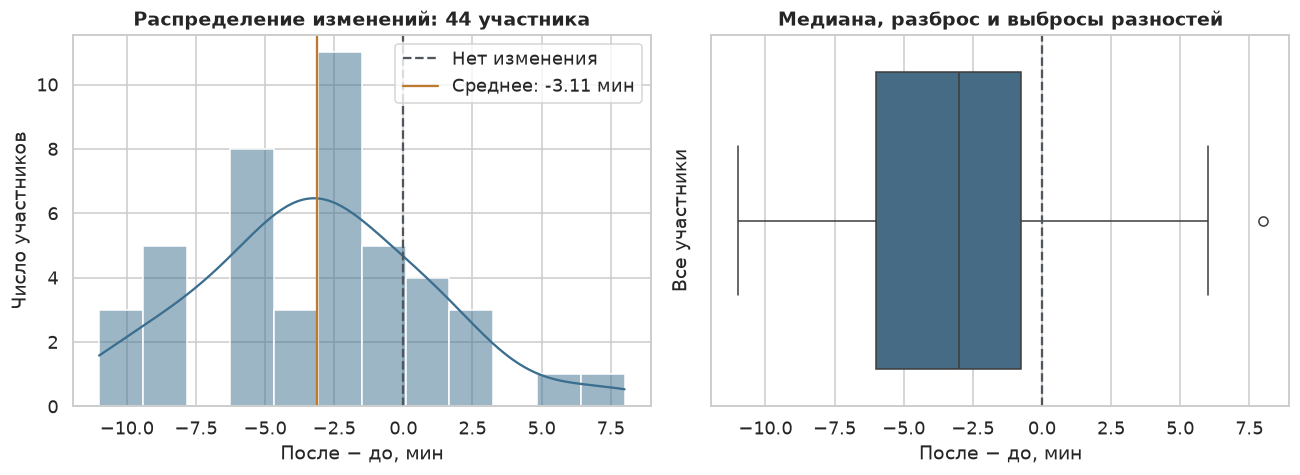

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(df_clean["diff"], bins=12, kde=True, color=BLUE, ax=axes[0])
axes[0].axvline(0, color=GRAY, linestyle="--", label="Нет изменения")
axes[0].axvline(
    df_clean["diff"].mean(), color=ORANGE,
    label=f"Среднее: {df_clean['diff'].mean():.2f} мин",
)
axes[0].set(title="Распределение изменений: 44 участника",
            xlabel="После − до, мин", ylabel="Число участников")
axes[0].legend()

sns.boxplot(x=df_clean["diff"], color=BLUE, ax=axes[1])
axes[1].axvline(0, color=GRAY, linestyle="--")
axes[1].set(title="Медиана, разброс и выбросы разностей",
            xlabel="После − до, мин", ylabel="Все участники")

plt.tight_layout()
plt.show()

**Описание графиков:** распределение смещено в отрицательную сторону: среднее изменение равно -3.11 мин, а медиана — -3 мин. Boxplot отмечает одно наблюдение с разностью +8 мин как выброс по правилу полутора межквартильных размахов. Его оставляем: оба исходных измерения находятся в допустимом диапазоне, и оснований считать запись ошибочной нет.

---
## Задание 4. Проверка нормальности разностей (2 балла)

**Что нужно сделать.** Выясните, можно ли считать разности `diff` приблизительно нормальными.

**Требования:**
1. Сформулируйте $H_0$ и $H_1$ для теста Шапиро-Уилка.
2. Проведите тест, выведите статистику $W$ и p-value.
3. Постройте Q-Q график (любой библиотекой).
4. Сформулируйте вывод (2–3 предложения): применим ли парный t-критерий? Что вы будете считать основным тестом, а что — проверочным?

### Подсказки

- Нормальность проверяется для **разностей**, а не для `before_min` и `after_min` по отдельности: парный t-тест — это тест для одной выборки `diff`.
- Тест: `stats.shapiro(...)`. Он возвращает статистику и p-value.
- Q-Q график: `stats.probplot(данные, dist="norm")` возвращает пару: теоретические и выборочные квантили, а также параметры прямой.
  Их можно нарисовать точками (`plotly` или `matplotlib`) и добавить линию.
- Помните: $p > 0.05$ означает «нет оснований отвергать нормальность», а не «нормальность доказана».
- Объём выборки (50) позволяет по центральной предельной теореме рассчитывать на приближённую нормальность среднего,
  даже если нормальность разностей не идеальна. Но график всё равно стоит посмотреть: нет ли сильных выбросов?

### Ваше решение

In [9]:
shapiro_result = stats.shapiro(df_clean["diff"])
print(f"Шапиро–Уилк: W = {shapiro_result.statistic:.4f}")
print(f"p-value = {shapiro_result.pvalue:.6g}")

Шапиро–Уилк: W = 0.9786
p-value = 0.578628


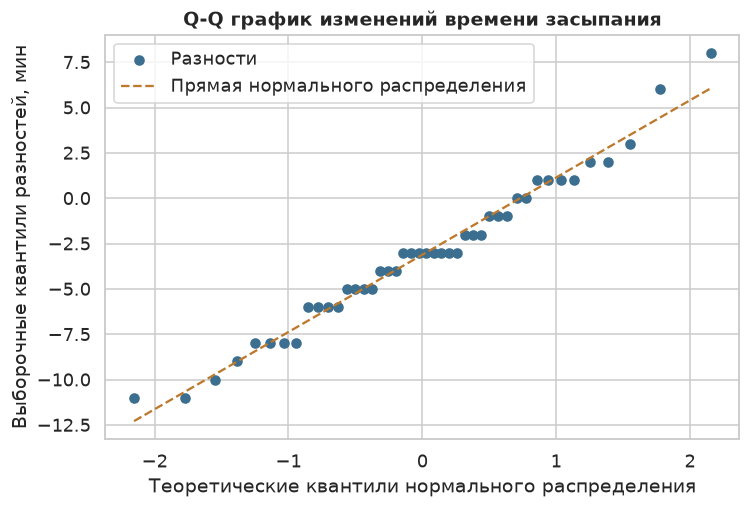

In [10]:
(theoretical, observed), (slope, intercept, _) = stats.probplot(
    df_clean["diff"], dist="norm"
)

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.scatter(theoretical, observed, color=BLUE, s=35, label="Разности")
ax.plot(theoretical, slope * theoretical + intercept,
        color=ORANGE, linestyle="--", label="Прямая нормального распределения")
ax.set(title="Q-Q график изменений времени засыпания",
       xlabel="Теоретические квантили нормального распределения",
       ylabel="Выборочные квантили разностей, мин")
ax.legend()
plt.tight_layout()
plt.show()

**Гипотезы Шапиро–Уилка:**

- $H_0$: разности взяты из нормального распределения.
- $H_1$: распределение разностей отличается от нормального.

**Вывод:** при $p = 0.5786 > 0.05$ нет оснований отвергать нормальность, но это не доказывает её. Точки Q-Q графика в целом идут вдоль прямой, с небольшими отклонениями по краям; сильного нарушения формы распределения не видно. Поэтому основной метод — парный t-критерий, а критерий Уилкоксона используем для проверки устойчивости вывода.

---
## Задание 5. Парный t-критерий и доверительный интервал (2 балла)

**Что нужно сделать.** Проверьте гипотезу из задания 1 парным t-критерием.

**Требования:**
1. Посчитайте **вручную** (через `numpy`/`pandas`): среднее разностей $\bar d$, стандартное отклонение $s_d$,
   стандартную ошибку, статистику $t$ и число степеней свободы.
2. Получите p-value по распределению Стьюдента вручную (`scipy.stats.t`).
3. Проведите тест готовой функцией и убедитесь, что результаты совпадают.
4. Постройте двусторонний 95% доверительный интервал для $\mu_d$.
5. Запишите решение по правилу из задания 1 и интерпретацию в одном предложении.

### Подсказки

- Формула статистики: $t = \dfrac{\bar d}{s_d / \sqrt{n}}$, число степеней свободы $\text{df} = n - 1$.
- Стандартное отклонение выборки: `.std(ddof=1)` (в pandas `ddof=1` по умолчанию, в numpy — нет!).
- p-value вручную: используйте функцию выживания `stats.t.sf(...)` или функцию распределения `stats.t.cdf(...)`.
  Подумайте, какой «хвост» нужен для вашей $H_1$: левый или правый. Для левостороннего теста p-value равно $P(T \le t_{\text{набл}})$.
- Готовая функция: `stats.ttest_rel(a, b, alternative=...)`. Порядок аргументов важен: тест сравнивает `a` с `b`,
  а параметр `alternative` принимает `"two-sided"`, `"less"`, `"greater"`. Выберите значения так, чтобы они соответствовали вашей $H_1$.
- Доверительный интервал: `stats.t.interval(0.95, df=..., loc=среднее, scale=стандартная_ошибка)`.
- Если ваш ручной и готовый p-value не совпадают, проверьте знак $t$ и выбранный «хвост».

### Ваше решение

In [11]:
d = df_clean["diff"]
n_pairs = len(d)
d_mean = d.mean()
d_std = d.std(ddof=1)
d_se = d_std / np.sqrt(n_pairs)
t_manual = d_mean / d_se
degrees_freedom = n_pairs - 1
p_manual = stats.t.cdf(t_manual, df=degrees_freedom)

display(pd.DataFrame({
    "Показатель": ["Число пар", "Среднее изменение, мин", "Стандартное отклонение, мин",
                   "Стандартная ошибка, мин", "t", "Степени свободы", "p-value"],
    "Значение": [n_pairs, d_mean, d_std, d_se, t_manual, degrees_freedom, p_manual],
}))

,Показатель,Значение
0,Число пар,44
1,"Среднее изменение, мин",-3.11364
2,"Стандартное отклонение, мин",4.18311
3,"Стандартная ошибка, мин",0.630628
4,t,-4.93736
5,Степени свободы,43
6,p-value,6.21219e-06


In [12]:
t_rel = stats.ttest_rel(
    df_clean["after_min"], df_clean["before_min"], alternative="less"
)
print(f"Готовый тест: t = {t_rel.statistic:.6f}, p-value = {t_rel.pvalue:.8g}")
calculations_match = np.allclose(
    [t_manual, p_manual], [t_rel.statistic, t_rel.pvalue], rtol=1e-12, atol=1e-12
)
print("Совпадение с ручным расчётом:", calculations_match)
assert calculations_match

Готовый тест: t = -4.937361, p-value = 6.2121873e-06
Совпадение с ручным расчётом: True


In [13]:
ci_low, ci_high = stats.t.interval(
    confidence=0.95, df=degrees_freedom, loc=d_mean, scale=d_se
)
display(pd.DataFrame({
    "Среднее изменение, мин": [d_mean],
    "Нижняя граница 95% ДИ, мин": [ci_low],
    "Верхняя граница 95% ДИ, мин": [ci_high],
}))

,"Среднее изменение, мин","Нижняя граница 95% ДИ, мин","Верхняя граница 95% ДИ, мин"
0,-3.11364,-4.38542,-1.84185


**Решение и интерпретация:** $p = 0.00000621 < 0.05$, поэтому отвергаем $H_0$ в пользу сокращения среднего времени засыпания; оценка изменения составляет -3.11 мин с двусторонним 95% ДИ [-4.39; -1.84] мин.

---
## Задание 6. Критерий Уилкоксона (1 балл)

**Что нужно сделать.** Повторите проверку непараметрическим критерием знаковых рангов и сравните с t-тестом.

**Требования:**
1. Запишите в одном предложении, что проверяет критерий Уилкоксона в этой задаче.
2. Проведите тест с той же альтернативой, что и в задании 5.
3. Сравните p-value двух тестов и напишите, согласуются ли выводы.

### Подсказки

- Функция: `stats.wilcoxon(...)`. Ей можно передать сразу столбец разностей.
- Параметр `alternative` работает так же, как у t-теста.
- Нулевые разности (участники без изменений) по умолчанию исключаются из расчёта. Это нормально; можно упомянуть в комментарии, сколько их было.
- Если p-value двух тестов отличаются в 1.5–3 раза, но решение одинаково, это не противоречие: тесты используют разную информацию.

### Ваше решение

In [14]:
wilcoxon_result = stats.wilcoxon(
    df_clean["diff"], alternative="less", zero_method="wilcox", method="asymptotic"
)
print(f"Нулевых разностей: {n_unchanged}; они не участвуют в ранжировании.")
print(f"Уилкоксон: W = {wilcoxon_result.statistic:.0f}, p-value = {wilcoxon_result.pvalue:.8g}")
print(f"Парный t-тест: p-value = {t_rel.pvalue:.8g}")

Нулевых разностей: 2; они не участвуют в ранжировании.
Уилкоксон: W = 120, p-value = 1.6252427e-05
Парный t-тест: p-value = 6.2121873e-06


**Что проверяет критерий:** при приблизительной симметрии распределения разностей проверяем, смещены ли они в отрицательную сторону относительно нуля.

В разностях есть нули и повторяющиеся значения, поэтому для p-value выбрано асимптотическое приближение, а нули исключены из ранжирования. Получено $p = 0.00001625$: как и у парного t-теста, оно меньше 0.05. Выводы согласуются, хотя p-value не обязаны совпадать: t-тест использует величины разностей, а Уилкоксон — их знаки и ранги.

---
## Задание 7. Типичная ошибка: непарный тест (2 балла)

**Что нужно сделать.** Намеренно примените **неверный** тест для независимых выборок и объясните разницу с результатом задания 5.

**Требования:**
1. Проведите тест Уэлча для двух независимых выборок (`before_min` и `after_min`) с той же альтернативой.
2. Выведите в таблице: $t$, p-value и стандартную ошибку для **парного** и **непарного** тестов, а также корреляцию Пирсона между `before_min` и `after_min`.
3. Изменилось ли решение по $H_0$ при $\alpha = 0.05$?
4. Объясните разницу в 3–4 предложениях: почему результаты различаются и какой тест надёжнее.
5. Постройте диаграмму рассеяния `before_min` vs `after_min` с диагональю $y = x$ и прокомментируйте её (1–2 предложения).

### Подсказки

- Функция: `stats.ttest_ind(a, b, equal_var=False, alternative=...)`. Порядок `a` и `b` должен быть таким же, как в задании 5.
- Стандартная ошибка непарного теста: $\sqrt{\dfrac{s_a^2}{n} + \dfrac{s_b^2}{n}}$. Стандартная ошибка парного теста: $s_d / \sqrt{n}$ (вы её уже считали).
- Корреляция: `df["before_min"].corr(df["after_min"])`.
- Для объяснения ответьте на вопросы: чем различаются люди между собой (сильно или слабо)? Сколько из этой вариации «вычитается» при переходе
  к разностям? Что происходит со знаменателем статистики $t$?
- Диаграмма рассеяния: `px.scatter` или `sns.scatterplot`. Диагональ: линия между точками `(min, min)` и `(max, max)`.
  Точки ниже диагонали — участники, у которых время засыпания уменьшилось.

### Ваше решение

In [15]:
t_ind = stats.ttest_ind(
    df_clean["after_min"], df_clean["before_min"],
    equal_var=False, alternative="less"
)
print(f"Ошибочный непарный тест: t = {t_ind.statistic:.6f}, p-value = {t_ind.pvalue:.8g}")

Ошибочный непарный тест: t = -1.271673, p-value = 0.10347165


In [16]:
se_ind = np.sqrt(
    df_clean["after_min"].var(ddof=1) / n_pairs
    + df_clean["before_min"].var(ddof=1) / n_pairs
)
correlation = df_clean["before_min"].corr(df_clean["after_min"])

comparison = pd.DataFrame({
    "Тест": ["Парный t-критерий", "Непарный Уэлча — ошибочно"],
    "t": [t_rel.statistic, t_ind.statistic],
    "p-value": [t_rel.pvalue, t_ind.pvalue],
    "Стандартная ошибка, мин": [d_se, se_ind],
})
display(comparison)
display(pd.DataFrame({
    "Показатель": ["Корреляция Пирсона между временем до и после"],
    "Значение": [correlation],
}))

,Тест,t,p-value,"Стандартная ошибка, мин"
0,Парный t-критерий,-4.93736,6.21219e-06,0.630628
1,Непарный Уэлча — ошибочно,-1.27167,0.103472,2.44846


,Показатель,Значение
0,Корреляция Пирсона между временем до и после,0.937178


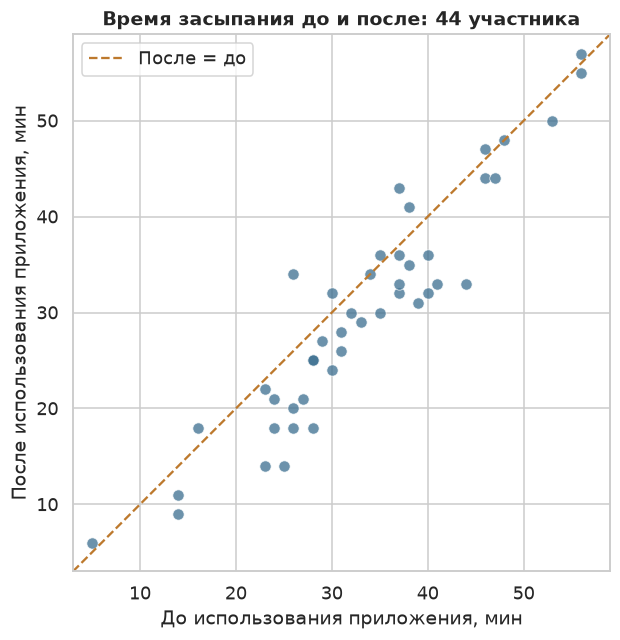

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 6))
sns.scatterplot(data=df_clean, x="before_min", y="after_min",
                color=BLUE, s=55, alpha=0.75, ax=ax)
lower = df_clean[["before_min", "after_min"]].min().min() - 2
upper = df_clean[["before_min", "after_min"]].max().max() + 2
ax.plot([lower, upper], [lower, upper], color=ORANGE,
        linestyle="--", label="После = до")
ax.set(xlim=(lower, upper), ylim=(lower, upper),
       title="Время засыпания до и после: 44 участника",
       xlabel="До использования приложения, мин",
       ylabel="После использования приложения, мин")
ax.set_aspect("equal", adjustable="box")
ax.legend()
plt.tight_layout()
plt.show()

**Решение изменилось?** Да: у парного теста $p = 0.00000621$, а у непарного $p = 0.1035 > 0.05$, поэтому второй расчёт не позволяет отвергнуть нулевую гипотезу.

**Объяснение разницы:** участники заметно различаются по исходному времени засыпания, а измерения до и после сильно связаны: $r = 0.937$. Парный тест сравнивает изменения у одних и тех же людей и тем самым учитывает эту связь. Непарный тест её игнорирует, поэтому его стандартная ошибка равна 2.448 мин вместо 0.631 мин, а модуль t-статистики меньше. Для этого дизайна корректен парный тест; непарный приведён только как учебный пример ошибки.

**Комментарий к диаграмме:** большинство участников находятся ниже линии равенства, то есть после использования приложения их время засыпания меньше. Точки вытянуты вдоль диагонали, что согласуется с высокой корреляцией измерений.

---
## Задание 8. Размер эффекта (1 балл)

**Что нужно сделать.** Оцените практическую значимость эффекта.

**Требования:**
1. Рассчитайте Cohen's $d$ для парных данных.
2. Интерпретируйте по шкале Коэна (≈0.2 — малый, ≈0.5 — средний, ≈0.8 — большой).
3. Выразите средний эффект в минутах и в процентах от среднего исходного времени засыпания.
4. Напишите 1–2 предложения: почему p-value недостаточно для ответа на вопрос «насколько это существенно?».

### Подсказки

- Формула: $d_z = \dfrac{\bar d}{s_d}$, где $\bar d$ и $s_d$ — среднее и стандартное отклонение разностей.
- У вас эффект отрицательный (время уменьшилось). Для интерпретации по шкале используйте **модуль** значения.
- Процент от исходного уровня: среднее изменение, делённое на `df["before_min"].mean()`, умноженное на 100.

### Ваше решение

In [18]:
cohen_dz = d_mean / d_std
percent_change = d_mean / df_clean["before_min"].mean() * 100

if abs(cohen_dz) < 0.2:
    effect_size = "пренебрежимо малый"
elif abs(cohen_dz) < 0.5:
    effect_size = "малый"
elif abs(cohen_dz) < 0.8:
    effect_size = "средний"
else:
    effect_size = "большой"

display(pd.DataFrame({
    "Показатель": ["Cohen's dz", "Среднее изменение, мин",
                   "Изменение от среднего исходного времени, %"],
    "Значение": [cohen_dz, d_mean, percent_change],
}))
print("Размер эффекта по шкале Коэна:", effect_size)

,Показатель,Значение
0,Cohen's dz,-0.744335
1,"Среднее изменение, мин",-3.11364
2,"Изменение от среднего исходного времени, %",-9.40288


Размер эффекта по шкале Коэна: средний


**Интерпретация:** $d_z = -0.744$; по модулю это средний эффект по условной шкале Коэна, а отрицательный знак означает сокращение времени. В среднем сокращение составляет 3.11 мин, или 9.4% от среднего времени до использования приложения; это отношение средних, а не средний индивидуальный процент.

Одного p-value недостаточно: оно не показывает, сколько минут составляет изменение. Практическую пользу нужно оценивать по величине эффекта и его доверительному интервалу, с учётом того, насколько такое сокращение важно пользователям.

---
## Задание 9. Гипотеза о доле улучшивших (1 балл)

**Что нужно сделать.** Проверьте ещё одну гипотезу, не использующую величину изменения, а только его **направление**:
*«более чем у половины участников время засыпания сократилось»*.

**Требования:**
1. Определите параметр $p$ и запишите $H_0$ и $H_1$.
2. Определите, кого учитывать в расчёте (что делать с участниками, у которых разность равна 0).
3. Проведите **биномиальный тест** и выведите p-value.
4. Сформулируйте вывод в одном предложении.
5. Рассчитайте долю улучшивших и её 95% доверительный интервал.

### Подсказки

- Параметр: $p$ — доля участников (среди тех, у кого время изменилось), у которых оно **сократилось**.
  Если приложение не работает, сокращение и увеличение равновероятны, то есть $p = 0.5$.
- Участников с `diff == 0` исключите из расчёта: они не дают информации о направлении. Укажите, сколько их было.
- Функция: `stats.binomtest(k, n, p=0.5, alternative=...)`, где `k` — число «успехов» (улучшившихся), `n` — число участников с ненулевой разностью.
- У результата теста есть метод `.proportion_ci(confidence_level=0.95)` для доверительного интервала доли. Внимание: интервал строится
  в соответствии с `alternative` теста (при односторонней альтернативе он тоже односторонний, одна из границ будет 0 или 1).
  Для обычного двустороннего интервала вызовите `binomtest` с `alternative="two-sided"`.
- Сравните этот тест с t-тестом: что он «теряет» по сравнению с ним (подсказка: он не учитывает величину изменений) и почему всё равно полезен
  (подсказка: не требует нормальности и устойчив к выбросам).

### Ваше решение

**Параметр:** $p$ — доля участников с сокращением времени среди тех,
у кого время изменилось.

**H₀:** $p = 0.5$ — сокращение и увеличение одинаково вероятны.

**H₁:** $p > 0.5$ — сокращение встречается чаще увеличения.

Из расчёта этой доли исключаем участников с `diff == 0`, но сохраняем их
в остальных заданиях. Проверка правосторонняя, потому что здесь речь идёт
о доле улучшивших, которая должна быть **больше** половины, а не о знаке
средней разности.

In [19]:
n_changed = int((df_clean["diff"] != 0).sum())
binomial_result = stats.binomtest(
    k=n_improved, n=n_changed, p=0.5, alternative="greater"
)
improved_share = n_improved / n_changed
improved_share_all = n_improved / n_pairs

share_ci = stats.binomtest(
    k=n_improved, n=n_changed, p=0.5, alternative="two-sided"
).proportion_ci(confidence_level=0.95, method="exact")

print(f"Без изменений, исключены из биномиального теста: {n_unchanged}")
print(f"Улучшились: {n_improved} из {n_changed} участников с изменением")
print(f"Доля среди участников с изменением: {improved_share:.2%}")
print(f"Доля среди всех участников анализа: {improved_share_all:.2%}")
print(f"Биномиальный тест: p-value = {binomial_result.pvalue:.8g}")
print(f"Двусторонний точный 95% ДИ доли: [{share_ci.low:.2%}; {share_ci.high:.2%}]")

Без изменений, исключены из биномиального теста: 2
Улучшились: 33 из 42 участников с изменением
Доля среди участников с изменением: 78.57%
Доля среди всех участников анализа: 75.00%
Биномиальный тест: p-value = 0.00013576962
Двусторонний точный 95% ДИ доли: [63.19%; 89.70%]


**Вывод:** $p = 0.00013577 < 0.05$, поэтому среди участников с ненулевым изменением есть основания считать долю улучшивших больше половины: 33 из 42, то есть 78.6%, с 95% ДИ [63.2%; 89.7%].

Этот тест учитывает только направление изменения и теряет информацию о его величине. Зато ему не нужна нормальность, а большая величина отдельного изменения не даёт такому участнику большего веса.

---
## Задание 10. Итоговые выводы (1 балл)

**Что нужно сделать.** Подготовьте заключение для руководителя продукта (не статистика!).

**Требования.** Сводная таблица результатов и текст из 5–7 предложений, содержащий:
1. ответ на бизнес-вопрос и размер выборки после очистки (сколько участников вошло в анализ и сколько исключено);
2. величину эффекта с доверительным интервалом (в минутах);
3. долю участников, которым приложение помогло;
4. упоминание, что вывод устойчив (согласие нескольких тестов) или, наоборот, что есть расхождения;
5. **минимум два ограничения** исследования (подумайте про контрольную группу, длительность, самоотчёты участников, добровольность);
6. рекомендацию: что делать дальше.

### Подсказки

- Таблицу соберите через `pd.DataFrame` со столбцами: метод, статистика, p-value, решение при $\alpha$.
  Включите в неё и ошибочный непарный тест, пометив его.
- Пишите без жаргона: вместо «p < 0.05» — «различие вряд ли случайно».
- Помните, что **без контрольной группы** нельзя утверждать, что именно приложение привело к улучшению: на время засыпания могли повлиять
  другие факторы (сезон, привычки, ожидания участников).
- Хорошая рекомендация конкретна: например, «провести контролируемое исследование с группой сравнения», а не «нужно больше данных».

### Ваше решение

In [20]:
results = pd.DataFrame({
    "Метод": ["Парный t-критерий", "Уилкоксон", "Биномиальный тест — статистика-доля",
              "Непарный Уэлча — ошибочный подход"],
    "Статистика": [t_rel.statistic, wilcoxon_result.statistic,
                    binomial_result.statistic, t_ind.statistic],
    "p-value": [t_rel.pvalue, wilcoxon_result.pvalue,
                binomial_result.pvalue, t_ind.pvalue],
})
results["Решение при α = 0.05"] = np.where(
    results["p-value"] < ALPHA, "Отвергаем H₀", "Нет оснований отвергать H₀"
)
display(results)

n_initial_participants = df["participant_id"].nunique()
n_excluded_participants = n_initial_participants - df_clean["participant_id"].nunique()
print(f"Исходных строк: {len(df)}; уникальных участников: {n_initial_participants}")
print(f"Исключено участников из-за неполных пар: {n_excluded_participants}")
print(f"Полных дубликатов строк удалено: {df.duplicated().sum()}")

,Метод,Статистика,p-value,Решение при α = 0.05
0,Парный t-критерий,-4.93736,6.21219e-06,Отвергаем H₀
1,Уилкоксон,120,1.62524e-05,Отвергаем H₀
2,Биномиальный тест — статистика-доля,0.785714,0.00013577,Отвергаем H₀
3,Непарный Уэлча — ошибочный подход,-1.27167,0.103472,Нет оснований отвергать H₀


Исходных строк: 52; уникальных участников: 50
Исключено участников из-за неполных пар: 6
Полных дубликатов строк удалено: 2


### Заключение для руководителя

После очистки в анализ вошли 44 из 50 уникальных участников: шесть исключены
из-за отсутствующих или ошибочных измерений времени.
После четырёх недель использования приложения среднее время засыпания
сократилось на 3.11 мин, или 9.4%
от исходного среднего; 95% доверительный интервал среднего сокращения —
от 1.84 до 4.39 мин.
Сокращение отмечено у 33 из 44 участников (75%), а среди 42 участников
с изменившимся временем — у 78.6%
(95% доверительный интервал: 63.2%–89.7%).
Две проверки, учитывающие повторные измерения, и проверка направлений
изменений дают согласованный результат в пользу сокращения времени.
Учебный расчёт для независимых групп даёт другой ответ, но он не подходит
для измерений одних и тех же людей до и после.
Контрольной группы нет, выборка небольшая и добровольная, время записывали
сами участники, а наблюдение было коротким, поэтому приписать изменение
именно приложению пока нельзя.
Следующий шаг — провести случайное распределение участников в группу
приложения и группу сравнения, продлить наблюдение и использовать более
объективную регистрацию сна.


---
## ★ Бонусное задание (+2 балла): одинаково ли приложение помогает разным возрастным группам?

**Что нужно сделать.** Выясните, различается ли средний эффект приложения между группами `до 35` и `35 и старше`, созданными вами в задании 2. Участников с неизвестным возрастом (`age_group` пропущен) исключите из этого задания и укажите, сколько их.

**Требования:**
1. Сформулируйте $H_0$ и $H_1$ (параметры: средние разности $\mu_{d,\text{до 35}}$ и $\mu_{d,\text{35+}}$). Выберите тип альтернативы и обоснуйте.
2. Постройте график (boxplot или violin) разностей `diff` по группам.
3. Для **каждой группы отдельно** выполните парный t-тест (помните про множественные проверки: как изменится порог значимости, если вы делаете 2 проверки?).
4. Сравните эффект между группами: проверьте нормальность `diff` в каждой группе, затем проведите подходящий тест для **двух независимых** выборок
   (какие это выборки теперь — парные или независимые, и почему?).
5. Сформулируйте вывод в 2–3 предложениях.

### Подсказки

- Здесь «объектами» сравнения становятся **разности** двух разных групп людей, а группы людей между собой независимы.
- Разбить данные: `df_clean[df_clean["age_group"] == "до 35"]["diff"]` или `df_clean.groupby("age_group")["diff"]`. Строки с пропуском в `age_group` при `groupby` по умолчанию отбрасываются, а при фильтрации по условию `!= "до 35"` они, наоборот, попадут во вторую группу, поэтому сравнивайте с обеими группами явно.
- Для сравнения двух независимых групп: `stats.ttest_ind(..., equal_var=False)` (Уэлч) и/или `stats.mannwhitneyu(...)`.
- Поправка Бонферрони: делите $\alpha$ на число проверок.
- В выводе укажите не только «различаются ли», но и **на сколько минут** различаются средние эффекты.

### Ваше решение

Не участвуют в возрастном анализе из-за неизвестного возраста: 4


,Участников,"Среднее изменение, мин","Стандартное отклонение, мин"
age_group,,,
до 35,19,-5.26316,3.60312
35 и старше,21,-1.28571,4.13694


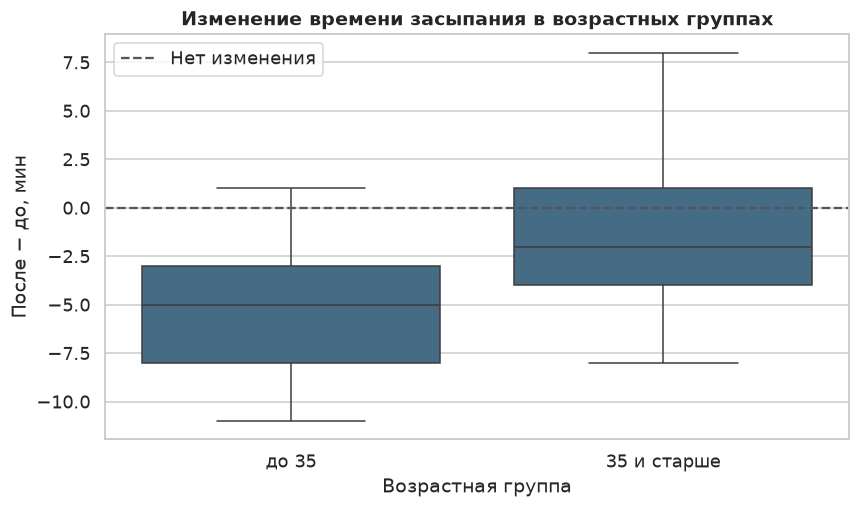

In [21]:
age_order = ["до 35", "35 и старше"]
df_age = df_clean.dropna(subset=["age_group"]).copy()
print("Не участвуют в возрастном анализе из-за неизвестного возраста:",
      df_clean["age_group"].isna().sum())

age_summary = (
    df_age.groupby("age_group")["diff"]
    .agg(["count", "mean", "std"])
    .reindex(age_order)
    .rename(columns={"count": "Участников", "mean": "Среднее изменение, мин",
                     "std": "Стандартное отклонение, мин"})
)
display(age_summary)

fig, ax = plt.subplots(figsize=(8, 4.8))
sns.boxplot(data=df_age, x="age_group", y="diff", order=age_order,
            color=BLUE, ax=ax)
ax.axhline(0, color=GRAY, linestyle="--", label="Нет изменения")
ax.set(title="Изменение времени засыпания в возрастных группах",
       xlabel="Возрастная группа", ylabel="После − до, мин")
ax.legend()
plt.tight_layout()
plt.show()

**Гипотезы межгруппового сравнения:**

$H_0: \mu_{d,\text{до 35}} = \mu_{d,\text{35+}}$.

$H_1: \mu_{d,\text{до 35}} \ne \mu_{d,\text{35+}}$.

Выбираем двустороннюю альтернативу: проверяем любое различие средних изменений, не задавая заранее, какая группа должна улучшиться сильнее. Внутри каждой группы измерения парные, но разности двух групп принадлежат разным людям и поэтому сравниваются как независимые выборки.

In [22]:
alpha_groups = ALPHA / 2
normality_rows = []
paired_rows = []

for group_name in age_order:
    group = df_age[df_age["age_group"] == group_name]
    normality = stats.shapiro(group["diff"])
    paired = stats.ttest_rel(
        group["after_min"], group["before_min"], alternative="less"
    )
    normality_rows.append({
        "Группа": group_name,
        "W": normality.statistic,
        "p-value Шапиро": normality.pvalue,
    })
    paired_rows.append({
        "Группа": group_name,
        "t": paired.statistic,
        "p-value": paired.pvalue,
        "Порог Бонферрони": alpha_groups,
        "Решение": "Отвергаем H₀" if paired.pvalue < alpha_groups
                   else "Нет оснований отвергать H₀",
    })

normality_by_age = pd.DataFrame(normality_rows)
paired_by_age = pd.DataFrame(paired_rows)
display(normality_by_age)
display(paired_by_age)

,Группа,W,p-value Шапиро
0,до 35,0.947854,0.363096
1,35 и старше,0.972607,0.789828


,Группа,t,p-value,Порог Бонферрони,Решение
0,до 35,-6.36715,2.6802e-06,0.025,Отвергаем H₀
1,35 и старше,-1.42421,0.0849008,0.025,Нет оснований отвергать H₀


В обеих группах нет оснований отвергать нормальность разностей: p-value равны 0.363 и 0.790; boxplot не показывает выраженных выбросов. Для сравнения средних разностей выбираем двусторонний тест Уэлча, который не требует равенства дисперсий. Поправка Бонферрони с порогом 0.025 применяется к двум отдельным проверкам сокращения внутри групп; межгрупповой вопрос проверяем отдельно при уровне 0.05.

In [23]:
diff_young = df_age.loc[df_age["age_group"] == "до 35", "diff"]
diff_older = df_age.loc[df_age["age_group"] == "35 и старше", "diff"]
age_welch = stats.ttest_ind(
    diff_young, diff_older, equal_var=False, alternative="two-sided"
)
age_effect_difference = diff_young.mean() - diff_older.mean()
age_difference_ci = age_welch.confidence_interval(confidence_level=0.95)

display(pd.DataFrame({
    "Разность средних изменений (до 35 минус 35+), мин": [age_effect_difference],
    "t Уэлча": [age_welch.statistic],
    "p-value": [age_welch.pvalue],
}))
print("95% ДИ разности средних изменений:",
      f"[{age_difference_ci.low:.2f}; {age_difference_ci.high:.2f}] мин")

,"Разность средних изменений (до 35 минус 35+), мин",t Уэлча,p-value
0,-3.97744,-3.24946,0.00242461


95% ДИ разности средних изменений: [-6.46; -1.50] мин


**Вывод:** у участников до 35 лет среднее сокращение составляет 5.26 мин, а в группе 35 лет и старше — 1.29 мин; четыре участника с неизвестным возрастом в этом сравнении не участвовали. При пороге 0.025 отдельная парная проверка подтверждает сокращение в младшей группе, а для старшей оснований недостаточно, что само по себе не доказывает отсутствия изменения. Отдельное сравнение групп даёт $p = 0.00242 < 0.05$: наблюдаемое среднее сокращение в младшей группе больше на 3.98 мин, но небольшой размер групп и отсутствие контроля ограничивают обобщение результата.

---
## Задание 11. Оформление проекта (2 балла)

В локальную папку проекта входят `solution.ipynb`, `requirements.txt`, `README.md` и `.gitignore`. В `solution.html` можно посмотреть выполненную работу без запуска Jupyter; данные создаются внутри ноутбука. Версии библиотек зафиксированы, полный запуск проверен в отдельном чистом окружении. Для проекта создан публичный репозиторий [VanVaanya/mirera-sleep-project](https://github.com/VanVaanya/mirera-sleep-project). Ссылка на проверку в Mirera пока не отправлена.

---
## Чек-лист самопроверки перед сдачей

**Анализ**
- [x] Данные очищены по правилам 1–4 в правильном порядке; контрольные числа (44 строки, 40 заполненных `age_group`) совпали; ведётся журнал очистки.
- [x] Столбец `age_group` создан корректно: возраст ровно 35 попадает в «35 и старше», пропуски возраста остались пропусками.
- [x] Все задания 3–10 выполнены на `df_clean`, а не на исходном `df`.
- [x] Гипотезы записаны формулами, определена разность и параметр $\mu_d$.
- [x] Направление $H_1$ согласовано со знаком разности `after − before` и параметром `alternative` во **всех** тестах.
- [x] Нормальность проверена для разностей, а не для исходных столбцов.
- [x] Ручной расчёт t-критерия совпадает с `ttest_rel`.
- [x] Для непарного теста порядок аргументов тот же, что и для парного.
- [x] Все графики подписаны (заголовок, оси).
- [x] Выводы написаны простым языком и содержат ограничения исследования.
- [x] Ноутбук выполняется целиком без ошибок (**Restart & Run All**).

**Проект**
- [ ] Репозиторий публичный: ссылка открывается без авторизации (проверьте в режиме инкогнито).
- [x] В локальной папке проекта есть `.ipynb`, `requirements.txt` и `README.md`.
- [x] В чистом окружении работает цепочка: `pip install -r requirements.txt` → открыть ноутбук → Restart & Run All.
- [ ] Ссылка отправлена не позднее чем за 3 дня до защиты.

---
## Что сдавать

1. **Оформить итог отдельным проектом**, в котором будет `.ipynb` с вашим решением.
2. **В проекте должен быть файл `requirements.txt`** со всеми необходимыми библиотеками.
3. **Расположить проект на GitHub** (или аналоге: GitLab, Bitbucket) **в виде публичного репозитория**.
4. **Предоставить ссылку на GitHub-репозиторий не позднее чем за 3 дня до защиты проекта.**

### Рекомендации по оформлению

**Структура репозитория:**

```
project-name/
├── README.md          # краткое описание проекта, как запустить, главные выводы
├── requirements.txt   # зависимости
└── solution.ipynb     # ваше решение
```

Отдельный файл с данными не нужен: данные создаются ячейкой генерации внутри ноутбука.

**`README.md`** (достаточно 5–10 строк): название и цель проекта, краткое описание данных, как установить зависимости и запустить ноутбук,
главный вывод (1–2 предложения).

**`requirements.txt`:**
- перечислите библиотеки, которые **реально используются** в вашем ноутбуке (по одной на строку); не копируйте вслепую полный вывод `pip freeze`;
- подумайте, какие библиотеки нужны не для самого анализа, а для **работы ноутбука**: например, `plotly` требует `nbformat` для отображения графиков в Jupyter;
- рекомендуется указывать версии (например, `pandas>=2.0`): узнать установленную версию можно через `pip show имя_библиотеки` или `pip list`.

**Проверка воспроизводимости.** Создайте чистое виртуальное окружение (`python -m venv .venv`), установите зависимости командой `pip install -r requirements.txt`
и выполните ноутбук командой **Restart & Run All**. Если появилась ошибка `ModuleNotFoundError`, значит, в `requirements.txt` не хватает библиотеки.

**Что не стоит публиковать:** папку виртуального окружения (`.venv`), личные токены и пароли. Для исключения лишнего добавьте файл `.gitignore`.

**Срок.** Ссылку на репозиторий нужно отправить **не позднее чем за 3 дня до защиты**. Репозиторий должен оставаться неизменным до защиты, чтобы защищаемая версия совпадала с проверенной.